# 07 — AN5 Engagement Sensitivity

This notebook executes the five canonical AN5 SQL investigations through the shared read-only PostgreSQL runner. SQL remains the single source of truth under `sql/04_analytics/`; no query text is duplicated here.

AN5 compares R0 (all source rows), R1 (exact six-column duplicate exclusion for metric calculation only), and R2 (maximum `sum_click` per five-column candidate key for sensitivity only). These are virtual query scenarios, not source-cleaning rules.

The notebook follows the direct-cell execution style of the historical WO-1 notebook: after the read-only preflight passes, each query cell executes directly without an interactive authorization prompt or per-query approval request. Execute cells individually from top to bottom; do not use Run All because each query scans the large activity table.

## 1. Environment setup

This cell locates the repository, imports the shared runner and AN5 helper, and initializes an in-memory evidence dictionary. It does not connect to PostgreSQL.

In [1]:
# 1. Locate the repository and import the canonical AN5 execution helpers.
from pathlib import Path
import sys
from IPython.display import display

_current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in [_current, *_current.parents]
        if (candidate / "src" / "analytics" / "db.py").is_file()
        and (candidate / "sql" / "04_analytics").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open Jupyter from the repository root or notebooks folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.run_an5 import (
    AN5_QUERY_IDS,
    EXPECTED_RESULT_SET_COUNTS,
    run_an5_query,
    verify_read_only_preflight,
)

query_results = {}
print("Project root:", PROJECT_ROOT)
print("AN5 query IDs:", AN5_QUERY_IDS)
print("Shared read-only runner imported:", callable(run_an5_query))

Project root: G:\OULAD-EdTech-Learning-Analytics-starter\OULAD-EdTech-Learning-Analytics
AN5 query IDs: ('AN5.01', 'AN5.02', 'AN5.03', 'AN5.04', 'AN5.05')
Shared read-only runner imported: True


## 2. Database identity and read-only preflight

The canonical AN0.01 query verifies the active database and both read-only settings. No AN5 query runs unless this preflight succeeds.

In [2]:
# 2. Verify the intended database and read-only session before AN5 execution.
preflight = verify_read_only_preflight()
query_results["PREFLIGHT.AN0.01"] = preflight
display(preflight["data"])
print("Preflight elapsed seconds:", preflight["elapsed_seconds"])
print("Preflight: PASS")

AN5 read-only preflight: {'database_name': True, 'transaction_read_only': True, 'default_transaction_read_only': True}


,database_name,database_user,current_schema,server_version,transaction_read_only,default_transaction_read_only,statement_timeout,lock_timeout
0,oulad_analytics,postgres,public,18.6,on,on,2min,5s


Preflight elapsed seconds: 0.019
Preflight: PASS


## 3. AN5.01 — Scenario and source-grain reconciliation

Returns three result sets: source repetition profile, R0/R1/R2 row-count bases, and activity-to-registration reconciliation. Review source counts, five-column candidate-key behavior, exact six-column duplicates, and unmatched activity.

In [3]:
# 3. Execute AN5.01 and retain all returned result sets.
result_an501 = run_an5_query("AN5.01")
query_results["AN5.01"] = result_an501
for item in result_an501["result_sets"]:
    print(f"Result set {item['statement_number']}: {item['rows_displayed']} rows; truncated={item['display_truncated']}")
    display(item["data"])
print("Batch seconds:", result_an501["elapsed_seconds"])

Result set 1: 1 rows; truncated=False


,r0_rows,distinct_five_column_keys,distinct_six_column_tuples,repeated_key_groups,rows_in_repeated_key_groups,excess_rows_over_five_column_keys,groups_with_multiple_sum_click_values,maximum_key_group_size,fully_identical_groups,excess_fully_identical_rows,r0_key_reconciliation,r1_tuple_reconciliation
0,10655280,8459320,9868110,1614505,3810465,2195960,1179074,10,642613,787170,True,True


Result set 2: 3 rows; truncated=False


,scenario,scenario_rows
0,R0,10655280
1,R1,9868110
2,R2,8459320


Result set 3: 66 rows; truncated=False


,scenario,code_module,code_presentation,registered_student_presentations,distinct_registered_students,activity_student_presentations,matched_activity_student_presentations,unmatched_activity_student_presentations,matched_activity_rows,unmatched_activity_rows,matched_sum_click,unmatched_sum_click
0,R0,AAA,2013J,383,383,378,378,0,180982,None,648494,None
1,R0,AAA,2014J,365,365,357,357,0,169316,None,598158,None
2,R0,BBB,2013B,1767,1767,1537,1537,0,403266,None,1347911,None
3,R0,BBB,2013J,2237,2237,1870,1870,0,452638,None,1378656,None
4,R0,BBB,2014B,1613,1613,1294,1294,0,273236,None,833865,None
...,...,...,...,...,...,...,...,...,...,...,...,...
61,R2,FFF,2014B,1500,1500,1363,1363,0,553107,None,2709585,None
62,R2,FFF,2014J,2365,2365,2121,2121,0,965223,None,4771098,None
63,R2,GGG,2013J,952,952,895,895,0,106230,None,422584,None
64,R2,GGG,2014B,833,833,773,773,0,87881,None,347138,None


Batch seconds: 660.747


## 4. AN5.02 — Student-presentation activity sensitivity

Compares recorded click volume, activity presence, student-active-day pairs, and student-active-site pairs using the same registered student-presentation denominator. Presentation-level and all-presentation summaries are returned.

In [4]:
# 4. Execute AN5.02 and retain its result set.
result_an502 = run_an5_query("AN5.02")
query_results["AN5.02"] = result_an502
for item in result_an502["result_sets"]:
    print(f"Result set {item['statement_number']}: {item['rows_displayed']} rows; truncated={item['display_truncated']}")
    display(item["data"])
print("Batch seconds:", result_an502["elapsed_seconds"])

Result set 1: 69 rows; truncated=False


,scenario,output_scope,code_module,code_presentation,registered_student_presentations,distinct_registered_students,activity_bearing_student_presentations,distinct_students_with_activity,student_presentations_without_activity,pct_registered_student_presentations_with_activity,matched_registered_activity_rows,matched_registered_sum_click,student_active_day_pairs,student_active_site_pairs
0,R0,ALL_PRESENTATIONS,NaN,NaN,32593,28785,29228,26074,3365,89.68,10655280,39605099,1808119,1960496
1,R0,MODULE_PRESENTATION,AAA,2013J,383,383,378,378,5,98.69,180982,648494,34072,24112
2,R0,MODULE_PRESENTATION,AAA,2014J,365,365,357,357,8,97.81,169316,598158,30703,20200
3,R0,MODULE_PRESENTATION,BBB,2013B,1767,1767,1537,1537,230,86.98,403266,1347911,78647,57068
4,R0,MODULE_PRESENTATION,BBB,2013J,2237,2237,1870,1870,367,83.59,452638,1378656,93548,67531
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,R2,MODULE_PRESENTATION,FFF,2014B,1500,1500,1363,1363,137,90.87,553107,2709585,96201,131009
65,R2,MODULE_PRESENTATION,FFF,2014J,2365,2365,2121,2121,244,89.68,965223,4771098,167164,215400
66,R2,MODULE_PRESENTATION,GGG,2013J,952,952,895,895,57,94.01,106230,422584,32352,29666
67,R2,MODULE_PRESENTATION,GGG,2014B,833,833,773,773,60,92.80,87881,347138,26352,24124


Batch seconds: 268.471


## 5. AN5.03 — Temporal activity sensitivity

Separates pre-course, in-course, and post-course activity, while retaining missing course metadata and unmatched registration keys. Relative days are not calendar dates.

In [5]:
# 5. Execute AN5.03 and retain its result set.
result_an503 = run_an5_query("AN5.03")
query_results["AN5.03"] = result_an503
for item in result_an503["result_sets"]:
    print(f"Result set {item['statement_number']}: {item['rows_displayed']} rows; truncated={item['display_truncated']}")
    display(item["data"])
print("Batch seconds:", result_an503["elapsed_seconds"])

Result set 1: 132 rows; truncated=False


,scenario,code_module,code_presentation,temporal_bucket,registration_match_status,scenario_activity_rows,recorded_sum_click,distinct_students,distinct_sites,distinct_relative_days,registered_student_presentations
0,R0,AAA,2013J,IN_COURSE,REGISTERED_STUDENT_PRESENTATION,170135,598871,376,209,269,383
1,R0,AAA,2013J,PRE_COURSE,REGISTERED_STUDENT_PRESENTATION,10847,49623,352,115,10,383
2,R0,AAA,2014J,IN_COURSE,REGISTERED_STUDENT_PRESENTATION,154808,534312,352,197,270,365
3,R0,AAA,2014J,PRE_COURSE,REGISTERED_STUDENT_PRESENTATION,14508,63846,335,149,24,365
4,R0,BBB,2013B,IN_COURSE,REGISTERED_STUDENT_PRESENTATION,383528,1282887,1513,315,241,1767
...,...,...,...,...,...,...,...,...,...,...,...
127,R2,GGG,2013J,PRE_COURSE,REGISTERED_STUDENT_PRESENTATION,6672,20223,572,49,16,952
128,R2,GGG,2014B,IN_COURSE,REGISTERED_STUDENT_PRESENTATION,83354,333408,766,122,240,833
129,R2,GGG,2014B,PRE_COURSE,REGISTERED_STUDENT_PRESENTATION,4527,13730,429,67,8,833
130,R2,GGG,2014J,IN_COURSE,REGISTERED_STUDENT_PRESENTATION,80499,315629,689,104,270,749


Batch seconds: 456.24


## 6. AN5.04 — Student ranking sensitivity

Ranks registered student-presentations within each module-presentation under each scenario. Reports average-rank Spearman correlation, absolute rank displacement, and top-decile overlap for R0/R1, R0/R2, and R1/R2. Ties at the top-decile boundary are included.

In [6]:
# 6. Execute AN5.04 and retain its result set.
result_an504 = run_an5_query("AN5.04")
query_results["AN5.04"] = result_an504
for item in result_an504["result_sets"]:
    print(f"Result set {item['statement_number']}: {item['rows_displayed']} rows; truncated={item['display_truncated']}")
    display(item["data"])
print("Batch seconds:", result_an504["elapsed_seconds"])

Result set 1: 66 rows; truncated=False


,code_module,code_presentation,scenario_a,scenario_b,registered_student_presentations,paired_student_presentations,spearman_rank_correlation,student_presentations_with_rank_change,mean_absolute_rank_change,median_absolute_rank_change,p90_absolute_rank_change,maximum_absolute_rank_change,top_decile_count_a,top_decile_count_b,top_decile_overlap,top_decile_union,top_decile_jaccard
0,AAA,2013J,R0,R1,383,383,0.999703,276,1.66,1.00,4.00,20.50000000000000000000,39,39,39,39,1.0000
1,AAA,2013J,R0,R2,383,383,0.998065,343,4.87,3.50,11.00,29.00000000000000000000,39,39,38,40,0.9500
2,AAA,2013J,R1,R2,383,383,0.998472,334,4.32,3.00,10.40,25.00000000000000000000,39,39,38,40,0.9500
3,AAA,2014J,R0,R1,365,365,0.999806,260,1.39,1.00,3.00,9.00000000000000000000,37,37,37,37,1.0000
4,AAA,2014J,R0,R2,365,365,0.998672,320,3.97,3.00,9.00,25.00000000000000000000,37,37,35,39,0.8974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,GGG,2014B,R0,R2,833,833,0.998118,737,10.42,7.50,26.00,60.00000000000000000000,84,84,79,89,0.8876
62,GGG,2014B,R1,R2,833,833,0.998883,729,7.85,5.00,19.00,44.00000000000000000000,84,84,80,88,0.9091
63,GGG,2014J,R0,R1,749,749,0.999581,631,4.20,3.00,10.00,38.00000000000000000000,75,75,73,77,0.9481
64,GGG,2014J,R0,R2,749,749,0.998360,653,8.45,5.50,20.00,58.50000000000000000000,75,75,72,78,0.9231


Batch seconds: 70.314


## 7. AN5.05 — Outcome-group activity sensitivity

Compares activity measures within final-result groups and module-presentations. Final results are retrospective descriptive labels, not predictors. The second result set diagnoses registration-to-profile matching and preserves missing or conflicting profile states.

In [7]:
# 7. Execute AN5.05 and retain both result sets.
result_an505 = run_an5_query("AN5.05")
query_results["AN5.05"] = result_an505
for item in result_an505["result_sets"]:
    print(f"Result set {item['statement_number']}: {item['rows_displayed']} rows; truncated={item['display_truncated']}")
    display(item["data"])
print("Batch seconds:", result_an505["elapsed_seconds"])

Result set 1: 264 rows; truncated=False


,scenario,code_module,code_presentation,outcome_group,registered_student_presentations,distinct_students,activity_bearing_student_presentations,student_presentations_without_activity,pct_with_recorded_activity,scenario_activity_rows,recorded_sum_click,mean_clicks_per_registered_student_presentation,median_clicks_per_registered_student_presentation,student_active_day_pairs,mean_active_days_per_registered_student_presentation,student_active_site_pairs,mean_active_sites_per_registered_student_presentation,valid_outcome_student_presentations,small_group_flag
0,R0,AAA,2013J,Distinction,20,20,20,0,100.00,21407,82419,4120.95,3148.5,3472,173.60,1767,88.35,20,True
1,R0,AAA,2013J,Fail,45,45,45,0,100.00,9141,30277,672.82,363,1931,42.91,1900,42.22,45,True
2,R0,AAA,2013J,Pass,258,258,258,0,100.00,135737,476559,1847.13,1439,26271,101.83,18058,69.99,258,False
3,R0,AAA,2013J,Withdrawn,60,60,55,5,91.67,14697,59239,987.32,579,2398,39.97,2387,39.78,60,True
4,R0,AAA,2014J,Distinction,24,24,24,0,100.00,21663,87215,3633.96,2469.5,3439,143.29,1848,77.00,24,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
259,R2,GGG,2014B,Withdrawn,100,100,66,34,66.00,2787,8438,84.38,26,836,8.36,975,9.75,100,False
260,R2,GGG,2014J,Distinction,127,127,127,0,100.00,23595,92885,731.38,596,7068,55.65,5433,42.78,127,False
261,R2,GGG,2014J,Fail,179,179,161,18,89.94,11262,39978,223.34,106,3083,17.22,3477,19.42,179,False
262,R2,GGG,2014J,Pass,317,317,317,0,100.00,49076,195143,615.59,537,14434,45.53,13017,41.06,317,False


Result set 2: 22 rows; truncated=False


,code_module,code_presentation,registered_student_presentation_keys,duplicate_registration_keys,unique_profile_matches,missing_profile_matches,duplicate_profile_matches,conflicting_final_result_keys,missing_final_result_keys,single_final_result_keys
0,AAA,2013J,383,0,383,0,0,0,0,383
1,AAA,2014J,365,0,365,0,0,0,0,365
2,BBB,2013B,1767,0,1767,0,0,0,0,1767
3,BBB,2013J,2237,0,2237,0,0,0,0,2237
4,BBB,2014B,1613,0,1613,0,0,0,0,1613
5,BBB,2014J,2292,0,2292,0,0,0,0,2292
6,CCC,2014B,1936,0,1936,0,0,0,0,1936
7,CCC,2014J,2498,0,2498,0,0,0,0,2498
8,DDD,2013B,1303,0,1303,0,0,0,0,1303
9,DDD,2013J,1938,0,1938,0,0,0,0,1938


Batch seconds: 282.843


# 8.1 Python-only review of retained AN5 outputs

The following cell uses only the bounded DataFrames already returned by AN5. It does not connect to PostgreSQL, rerun SQL, read the full student_vle table, or modify source data. It produces compact scenario comparisons and validation summaries that are not fully visible in the default pandas notebook display.

In [11]:
# 9. Derive compact review tables from the already-retained AN5 result sets.
# This cell is Python-only: it does not open a database connection or execute SQL.
import pandas as pd
from IPython.display import display

_required = ("AN5.01", "AN5.02", "AN5.03", "AN5.04", "AN5.05")
_missing = [query_id for query_id in _required if query_id not in query_results]

if _missing:
    print(
        "IN-MEMORY REVIEW NOT AVAILABLE. Missing retained outputs:",
        _missing,
        "| No SQL was executed. Do not rerun the large queries solely to bypass this message."
    )
else:
    _truncated = [
        (query_id, item["statement_number"])
        for query_id in _required
        for item in query_results[query_id]["result_sets"]
        if item["display_truncated"]
    ]

    if _truncated:
        print("REVIEW BLOCKED: runner-level row-cap truncation detected:", _truncated)
    else:
        # Preserve complete bounded result sets locally before deriving summaries.
        # outputs/an5/ is ignored by Git and contains no connection credentials.
        import json
        from datetime import datetime, timezone
        from pathlib import Path

        AN5_OUTPUT_DIR = Path(PROJECT_ROOT) / "outputs" / "an5"
        AN5_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        _export_manifest = {
            "generated_at_utc": datetime.now(timezone.utc).isoformat(),
            "source": "already-retained AN5 notebook result sets",
            "sql_rerun": False,
            "queries": [],
        }
        for _query_id in _required:
            _query_result = query_results[_query_id]
            _query_record = {
                "query_id": _query_id,
                "elapsed_seconds": _query_result["elapsed_seconds"],
                "statement_timeout_ms": _query_result["statement_timeout_ms"],
                "result_set_count": _query_result["result_set_count"],
                "result_sets": [],
            }
            for _item in _query_result["result_sets"]:
                _filename = (
                    f"{_query_id.replace('.', '_')}_result_"
                    f"{_item['statement_number']:02d}.csv"
                )
                _item["data"].to_csv(AN5_OUTPUT_DIR / _filename, index=False)
                _query_record["result_sets"].append({
                    "statement_number": _item["statement_number"],
                    "file": _filename,
                    "rows_exported": len(_item["data"]),
                    "display_truncated": _item["display_truncated"],
                })
            _export_manifest["queries"].append(_query_record)

        _manifest_path = AN5_OUTPUT_DIR / "an5_review_manifest.json"
        _manifest_path.write_text(
            json.dumps(_export_manifest, indent=2),
            encoding="utf-8",
        )
        print("Complete retained AN5 result sets exported to:", AN5_OUTPUT_DIR)
        print("Export manifest:", _manifest_path)

        def _an5_frame(query_id, result_set_number=1):
            return query_results[query_id]["result_sets"][result_set_number - 1]["data"].copy()

        # A. AN5.01 — scenario row counts and activity/registration reconciliation.
        _source_profile = _an5_frame("AN5.01", 1).iloc[0]
        _scenario_counts = _an5_frame("AN5.01", 2)
        _r0_rows = int(_scenario_counts.loc[_scenario_counts["scenario"] == "R0", "scenario_rows"].iloc[0])
        _scenario_counts["rows_removed_vs_R0"] = _r0_rows - _scenario_counts["scenario_rows"]
        _scenario_counts["pct_removed_vs_R0"] = (
            100 * _scenario_counts["rows_removed_vs_R0"] / _r0_rows
        ).round(2)
        print("AN5.01 — source profile")
        display(pd.DataFrame([_source_profile]))
        print("AN5.01 — scenario row counts")
        display(_scenario_counts)

        _match = _an5_frame("AN5.01", 3)
        _match_summary = (
            _match.groupby("scenario", as_index=False)
            .agg(
                module_presentations=("code_presentation", "size"),
                registered_student_presentations=("registered_student_presentations", "sum"),
                activity_student_presentations=("activity_student_presentations", "sum"),
                matched_activity_student_presentations=("matched_activity_student_presentations", "sum"),
                unmatched_activity_student_presentations=("unmatched_activity_student_presentations", "sum"),
                matched_activity_rows=("matched_activity_rows", "sum"),
                unmatched_activity_rows=("unmatched_activity_rows", "sum"),
            )
        )
        print("AN5.01 — activity/registration reconciliation")
        display(_match_summary)

        # B. AN5.02 — exact R0/R1/R2 measure changes at the common registered denominator.
        _activity = _an5_frame("AN5.02", 1)
        _overall = _activity.loc[_activity["output_scope"] == "ALL_PRESENTATIONS"].copy()
        _base = _overall.loc[_overall["scenario"] == "R0"].iloc[0]
        _overall["click_delta_vs_R0"] = _overall["matched_registered_sum_click"] - _base["matched_registered_sum_click"]
        _overall["click_delta_pct_vs_R0"] = (
            100 * _overall["click_delta_vs_R0"] / _base["matched_registered_sum_click"]
        ).round(2)
        _overall["activity_row_delta_vs_R0"] = _overall["matched_registered_activity_rows"] - _base["matched_registered_activity_rows"]
        _overall["activity_row_delta_pct_vs_R0"] = (
            100 * _overall["activity_row_delta_vs_R0"] / _base["matched_registered_activity_rows"]
        ).round(2)
        _overall["coverage_delta_pp_vs_R0"] = (
            _overall["pct_registered_student_presentations_with_activity"]
            - _base["pct_registered_student_presentations_with_activity"]
        ).round(2)
        _invariant_columns = [
            "registered_student_presentations",
            "distinct_registered_students",
            "activity_bearing_student_presentations",
            "distinct_students_with_activity",
            "student_presentations_without_activity",
            "pct_registered_student_presentations_with_activity",
            "student_active_day_pairs",
            "student_active_site_pairs",
        ]
        _activity_invariants = pd.DataFrame(
            [
                {"measure": column, "same_across_R0_R1_R2": _overall[column].nunique(dropna=False) == 1}
                for column in _invariant_columns
            ]
        )
        print("AN5.02 — overall scenario comparison")
        display(_overall.sort_values("scenario"))
        print("AN5.02 — expected-presence invariants")
        display(_activity_invariants)

        # C. AN5.03 — temporal categories; sums of distinct counts remain presentation-level sums.
        _temporal = _an5_frame("AN5.03", 1)
        _temporal_summary = (
            _temporal.groupby(
                ["scenario", "temporal_bucket", "registration_match_status"],
                dropna=False,
                as_index=False,
            )
            .agg(
                module_presentation_bucket_rows=("code_module", "size"),
                scenario_activity_rows=("scenario_activity_rows", "sum"),
                recorded_sum_click=("recorded_sum_click", "sum"),
                sum_of_presentation_distinct_students=("distinct_students", "sum"),
                sum_of_presentation_distinct_sites=("distinct_sites", "sum"),
                sum_of_presentation_distinct_relative_days=("distinct_relative_days", "sum"),
            )
        )
        print("AN5.03 — temporal and registration-match summary")
        display(_temporal_summary)

                # D. AN5.04 — ranking sensitivity across all module-presentations.
        _ranking = _an5_frame("AN5.04", 1)

        # Normalize numeric fields returned by the database driver.
        _rank_numeric_columns = [
            "spearman_rank_correlation",
            "mean_absolute_rank_change",
            "maximum_absolute_rank_change",
            "top_decile_jaccard",
        ]

        for _column in _rank_numeric_columns:
            _ranking[_column] = pd.to_numeric(
                _ranking[_column],
                errors="raise",
            )

        _ranking_summary = (
            _ranking.groupby(["scenario_a", "scenario_b"], as_index=False)
            .agg(
                module_presentations=("code_module", "size"),
                paired_student_presentations=("paired_student_presentations", "sum"),
                spearman_min=("spearman_rank_correlation", "min"),
                spearman_median=("spearman_rank_correlation", "median"),
                spearman_max=("spearman_rank_correlation", "max"),
                student_presentations_with_rank_change=(
                    "student_presentations_with_rank_change", "sum"
                ),
                mean_of_presentation_mean_rank_change=(
                    "mean_absolute_rank_change", "mean"
                ),
                top_decile_jaccard_min=("top_decile_jaccard", "min"),
                top_decile_jaccard_median=("top_decile_jaccard", "median"),
            )
        )

        print("AN5.04 — ranking sensitivity summary")
        display(_ranking_summary)

        print("AN5.04 — five lowest top-decile overlaps")
        print(
            "Rows with missing top-decile overlap:",
            int(_ranking["top_decile_jaccard"].isna().sum()),
        )

        display(
            _ranking.nsmallest(5, "top_decile_jaccard")[
                [
                    "code_module",
                    "code_presentation",
                    "scenario_a",
                    "scenario_b",
                    "spearman_rank_correlation",
                    "mean_absolute_rank_change",
                    "maximum_absolute_rank_change",
                    "top_decile_jaccard",
                ]
            ]
        )
        # E. AN5.05 — outcome-group summaries at student-presentation grain.
        _outcomes = _an5_frame("AN5.05", 1)
        _outcome_summary = (
            _outcomes.groupby(["scenario", "outcome_group"], dropna=False, as_index=False)
            .agg(
                registered_student_presentations=("registered_student_presentations", "sum"),
                activity_bearing_student_presentations=("activity_bearing_student_presentations", "sum"),
                student_presentations_without_activity=("student_presentations_without_activity", "sum"),
                recorded_sum_click=("recorded_sum_click", "sum"),
                student_active_day_pairs=("student_active_day_pairs", "sum"),
                student_active_site_pairs=("student_active_site_pairs", "sum"),
                small_module_presentation_groups=("small_group_flag", "sum"),
                module_presentations=("code_module", "size"),
                valid_outcome_student_presentations=("valid_outcome_student_presentations", "sum"),
            )
        )
        _outcome_summary["activity_coverage_pct"] = (
            100 * _outcome_summary["activity_bearing_student_presentations"]
            / _outcome_summary["registered_student_presentations"]
        ).round(2)
        _outcome_summary["mean_clicks_per_student_presentation"] = (
            _outcome_summary["recorded_sum_click"]
            / _outcome_summary["registered_student_presentations"]
        ).round(2)
        _outcome_summary["mean_active_days_per_student_presentation"] = (
            _outcome_summary["student_active_day_pairs"]
            / _outcome_summary["registered_student_presentations"]
        ).round(2)
        _outcome_summary["mean_active_sites_per_student_presentation"] = (
            _outcome_summary["student_active_site_pairs"]
            / _outcome_summary["registered_student_presentations"]
        ).round(2)
        print("AN5.05 — outcome-group summaries (student-presentation totals, not unique people)")
        display(_outcome_summary)

        _profiles = _an5_frame("AN5.05", 2)
        _profile_summary = _profiles[
            [
                "registered_student_presentation_keys",
                "duplicate_registration_keys",
                "unique_profile_matches",
                "missing_profile_matches",
                "duplicate_profile_matches",
                "conflicting_final_result_keys",
                "missing_final_result_keys",
                "single_final_result_keys",
            ]
        ].sum().to_frame("total").T
        print("AN5.05 — registration-to-profile diagnostic totals")
        display(_profile_summary)

        print("AN5 Python-only review complete. No SQL was executed by this cell.")

Complete retained AN5 result sets exported to: G:\OULAD-EdTech-Learning-Analytics-starter\OULAD-EdTech-Learning-Analytics\outputs\an5
Export manifest: G:\OULAD-EdTech-Learning-Analytics-starter\OULAD-EdTech-Learning-Analytics\outputs\an5\an5_review_manifest.json
AN5.01 — source profile


,r0_rows,distinct_five_column_keys,distinct_six_column_tuples,repeated_key_groups,rows_in_repeated_key_groups,excess_rows_over_five_column_keys,groups_with_multiple_sum_click_values,maximum_key_group_size,fully_identical_groups,excess_fully_identical_rows,r0_key_reconciliation,r1_tuple_reconciliation
0,10655280,8459320,9868110,1614505,3810465,2195960,1179074,10,642613,787170,True,True


AN5.01 — scenario row counts


,scenario,scenario_rows,rows_removed_vs_R0,pct_removed_vs_R0
0,R0,10655280,0,0.00
1,R1,9868110,787170,7.39
2,R2,8459320,2195960,20.61


AN5.01 — activity/registration reconciliation


,scenario,module_presentations,registered_student_presentations,activity_student_presentations,matched_activity_student_presentations,unmatched_activity_student_presentations,matched_activity_rows,unmatched_activity_rows
0,R0,22,32593,29228,29228,0,10655280,0
1,R1,22,32593,29228,29228,0,9868110,0
2,R2,22,32593,29228,29228,0,8459320,0


... (11 outputs left out)

,scenario,outcome_group,registered_student_presentations,activity_bearing_student_presentations,student_presentations_without_activity,recorded_sum_click,student_active_day_pairs,student_active_site_pairs,small_module_presentation_groups,module_presentations,valid_outcome_student_presentations,activity_coverage_pct,mean_clicks_per_student_presentation,mean_active_days_per_student_presentation,mean_active_sites_per_student_presentation
0,R0,Distinction,3024,3024,0,8064279,332769,309799,5,22,3024,100.00,2666.76,110.04,102.45
1,R0,Fail,7052,6678,374,4596865,233965,303786,2,22,7052,94.70,651.85,33.18,43.08
2,R0,Pass,12361,12358,3,23755478,1075957,1100810,0,22,12361,99.98,1921.81,87.04,89.06
3,R0,Withdrawn,10156,7168,2988,3188477,165428,246101,3,22,10156,70.58,313.95,16.29,24.23
4,R1,Distinction,3024,3024,0,7785064,332769,309799,5,22,3024,100.00,2574.43,110.04,102.45
5,R1,Fail,7052,6678,374,4455342,233965,303786,2,22,7052,94.70,631.78,33.18,43.08
6,R1,Pass,12361,12358,3,23016181,1075957,1100810,0,22,12361,99.98,1862.00,87.04,89.06
7,R1,Withdrawn,10156,7168,2988,3086476,165428,246101,3,22,10156,70.58,303.91,16.29,24.23
8,R2,Distinction,3024,3024,0,6881136,332769,309799,5,22,3024,100.00,2275.51,110.04,102.45
9,R2,Fail,7052,6678,374,4052901,233965,303786,2,22,7052,94.70,574.72,33.18,43.08


AN5.05 — registration-to-profile diagnostic totals


,registered_student_presentation_keys,duplicate_registration_keys,unique_profile_matches,missing_profile_matches,duplicate_profile_matches,conflicting_final_result_keys,missing_final_result_keys,single_final_result_keys
total,32593,0,32593,0,0,0,0,32593


AN5 Python-only review complete. No SQL was executed by this cell.


## 8.2 — Visual representation of AN5 sensitivity results

This section presents a compact visual summary of the retained AN5 results using the review tables already derived in the preceding Python-only cell.

The visualizations cover:

1. Scenario-level source row counts.
2. Changes in recorded activity rows and click volume.
3. Stability of activity coverage, active-day pairs, and active-site pairs.
4. The distribution of recorded activity across temporal buckets.
5. Ranking sensitivity across scenario comparisons.
6. Mean recorded clicks across final-result groups.

All figures use the existing in-memory AN5 outputs. No database connection is opened, no SQL is executed, and no additional source data is loaded.

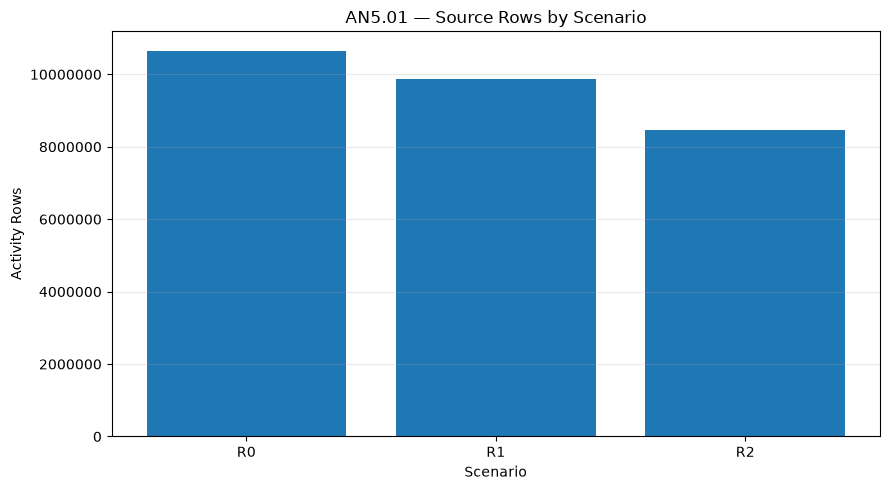

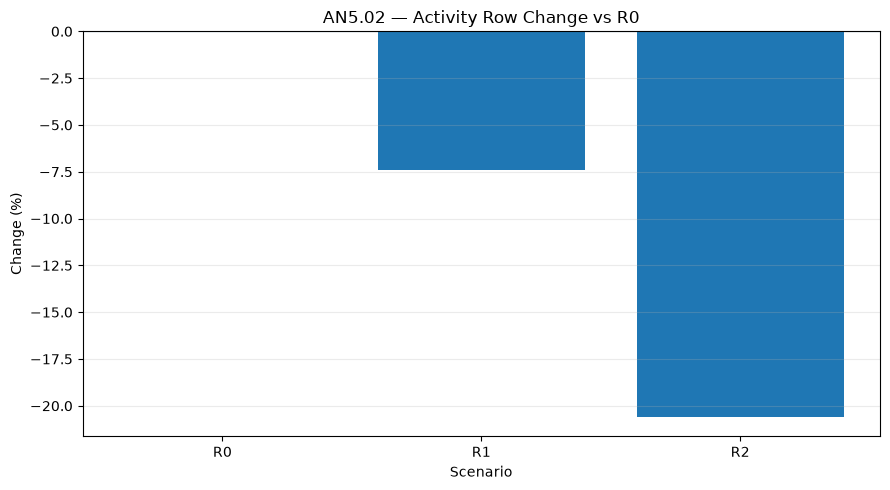

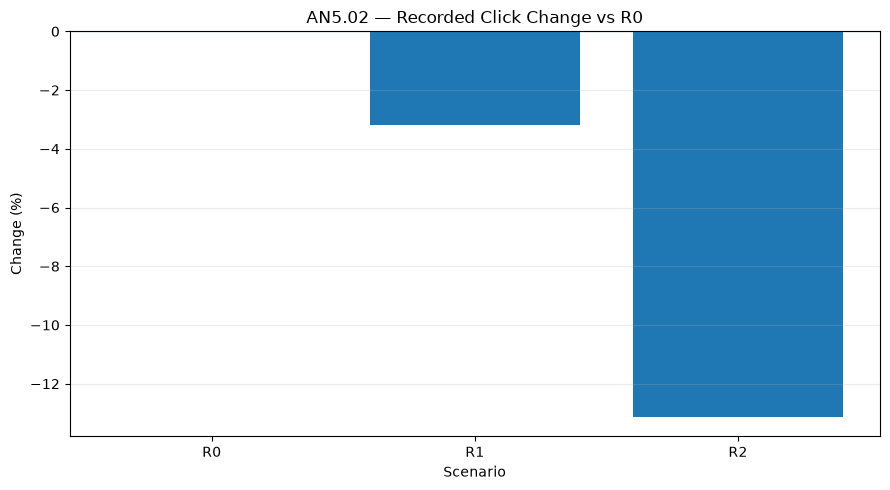

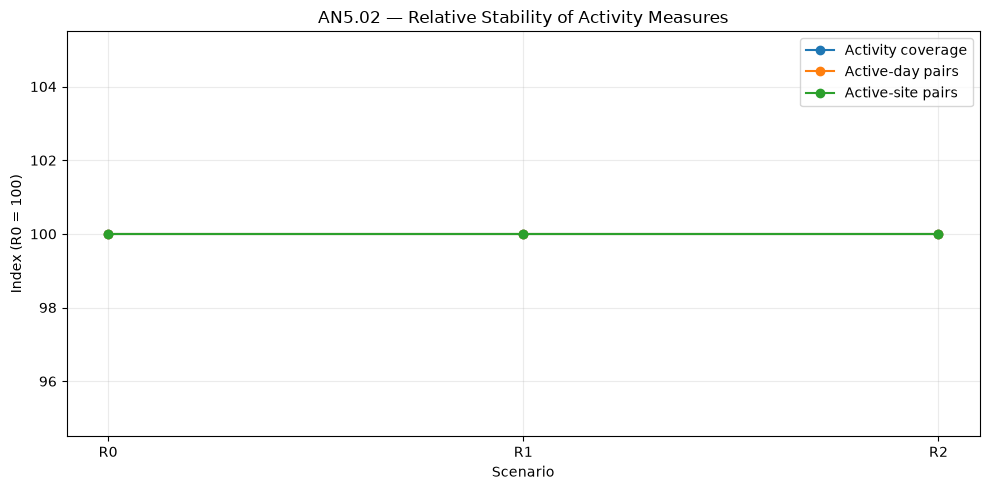

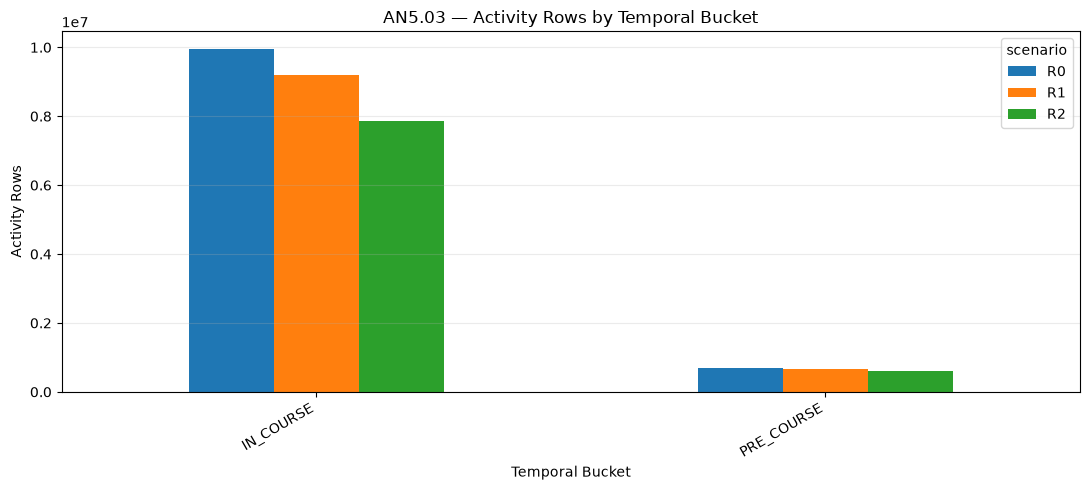

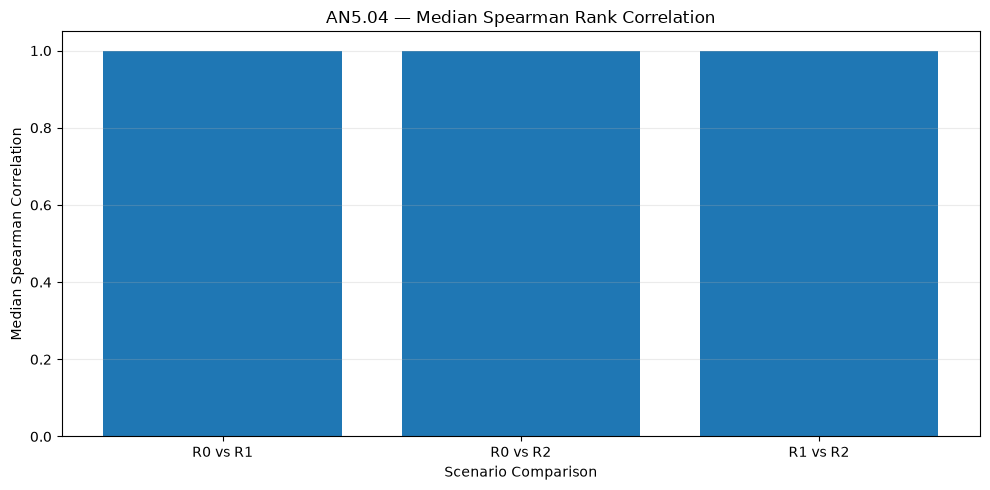

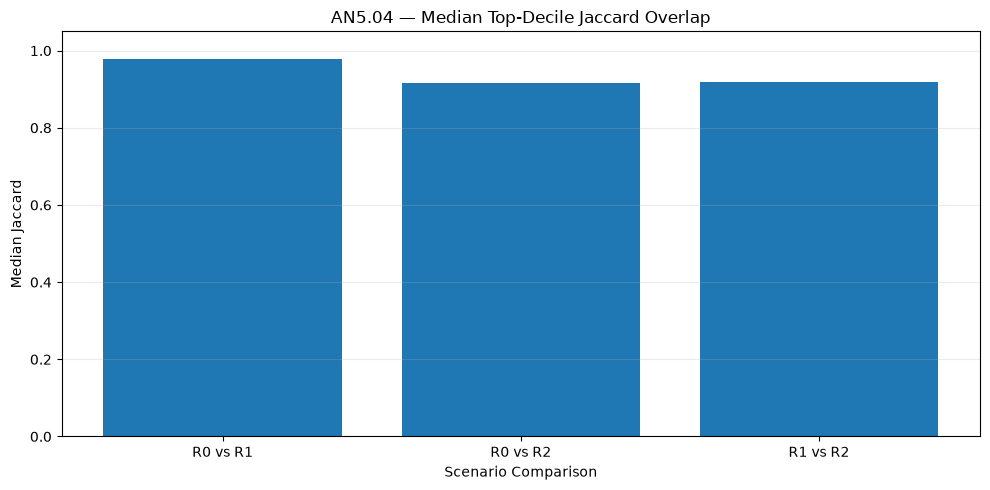

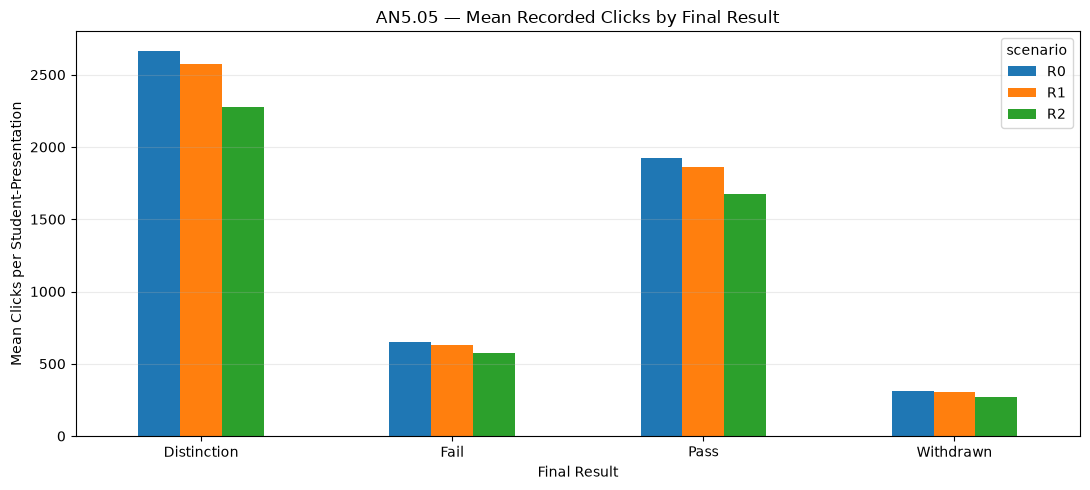

AN5 visual summaries generated from retained outputs. No SQL was executed.


In [13]:

# 8. Generate visual summaries from the already-retained AN5 review tables.
# This cell is Python-only and does not connect to PostgreSQL or execute SQL.

import matplotlib.pyplot as plt
import pandas as pd

SCENARIO_ORDER = ["R0", "R1", "R2"]

# 1. Scenario-level source row counts.
scenario_plot = _scenario_counts.copy()
scenario_plot["scenario"] = pd.Categorical(
    scenario_plot["scenario"],
    categories=SCENARIO_ORDER,
    ordered=True,
)
scenario_plot = scenario_plot.sort_values("scenario")

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(
    scenario_plot["scenario"].astype(str),
    scenario_plot["scenario_rows"],
)
ax.set_title("AN5.01 — Source Rows by Scenario")
ax.set_xlabel("Scenario")
ax.set_ylabel("Activity Rows")
ax.ticklabel_format(axis="y", style="plain")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


# 2. Relative changes in activity rows and recorded clicks.
overall_plot = _overall.copy()
overall_plot["scenario"] = pd.Categorical(
    overall_plot["scenario"],
    categories=SCENARIO_ORDER,
    ordered=True,
)
overall_plot = overall_plot.sort_values("scenario")

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(
    overall_plot["scenario"].astype(str),
    overall_plot["activity_row_delta_pct_vs_R0"],
)
ax.set_title("AN5.02 — Activity Row Change vs R0")
ax.set_xlabel("Scenario")
ax.set_ylabel("Change (%)")
ax.axhline(0, linewidth=0.8)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(
    overall_plot["scenario"].astype(str),
    overall_plot["click_delta_pct_vs_R0"],
)
ax.set_title("AN5.02 — Recorded Click Change vs R0")
ax.set_xlabel("Scenario")
ax.set_ylabel("Change (%)")
ax.axhline(0, linewidth=0.8)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


# 3. Relative stability of coverage, active days, and active sites.
robust_metrics = {
    "Activity coverage": "pct_registered_student_presentations_with_activity",
    "Active-day pairs": "student_active_day_pairs",
    "Active-site pairs": "student_active_site_pairs",
}

robust_plot = overall_plot[["scenario"]].copy()

for label, column in robust_metrics.items():
    baseline = overall_plot.loc[
        overall_plot["scenario"] == "R0", column
    ].iloc[0]

    robust_plot[label] = (
        100 * overall_plot[column] / baseline
        if baseline != 0
        else float("nan")
    )

fig, ax = plt.subplots(figsize=(10, 5))
for metric in robust_metrics:
    ax.plot(
        robust_plot["scenario"].astype(str),
        robust_plot[metric],
        marker="o",
        label=metric,
    )

ax.set_title("AN5.02 — Relative Stability of Activity Measures")
ax.set_xlabel("Scenario")
ax.set_ylabel("Index (R0 = 100)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# 4. Temporal activity distribution by scenario.
temporal_plot = (
    _temporal_summary
    .groupby(
        ["scenario", "temporal_bucket"],
        dropna=False,
        observed=False,
        as_index=False,
    )
    .agg(
        activity_rows=("scenario_activity_rows", "sum"),
        recorded_clicks=("recorded_sum_click", "sum"),
    )
)

temporal_rows = temporal_plot.pivot(
    index="temporal_bucket",
    columns="scenario",
    values="activity_rows",
).reindex(columns=SCENARIO_ORDER).fillna(0)

temporal_rows.plot(
    kind="bar",
    figsize=(11, 5),
)
plt.title("AN5.03 — Activity Rows by Temporal Bucket")
plt.xlabel("Temporal Bucket")
plt.ylabel("Activity Rows")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


# 5. Ranking sensitivity across scenario comparisons.
ranking_plot = _ranking_summary.copy()
ranking_plot["comparison"] = (
    ranking_plot["scenario_a"].astype(str)
    + " vs "
    + ranking_plot["scenario_b"].astype(str)
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(
    ranking_plot["comparison"],
    ranking_plot["spearman_median"],
)
ax.set_title("AN5.04 — Median Spearman Rank Correlation")
ax.set_xlabel("Scenario Comparison")
ax.set_ylabel("Median Spearman Correlation")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(
    ranking_plot["comparison"],
    ranking_plot["top_decile_jaccard_median"],
)
ax.set_title("AN5.04 — Median Top-Decile Jaccard Overlap")
ax.set_xlabel("Scenario Comparison")
ax.set_ylabel("Median Jaccard")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


# 6. Mean recorded clicks by final-result group and scenario.
outcome_plot = _outcome_summary.copy()

# Explicitly convert the plotting measure to numeric before pivoting.
outcome_plot["mean_clicks_per_student_presentation"] = pd.to_numeric(
    outcome_plot["mean_clicks_per_student_presentation"],
    errors="raise",
)

outcome_plot["scenario"] = pd.Categorical(
    outcome_plot["scenario"],
    categories=SCENARIO_ORDER,
    ordered=True,
)

outcome_clicks = outcome_plot.pivot(
    index="outcome_group",
    columns="scenario",
    values="mean_clicks_per_student_presentation",
).reindex(columns=SCENARIO_ORDER)

# Ensure all pivoted scenario columns are numeric.
outcome_clicks = outcome_clicks.apply(
    pd.to_numeric,
    errors="raise",
)

ax = outcome_clicks.plot(
    kind="bar",
    figsize=(11, 5),
)

ax.set_title("AN5.05 — Mean Recorded Clicks by Final Result")
ax.set_xlabel("Final Result")
ax.set_ylabel("Mean Clicks per Student-Presentation")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

print(
    "AN5 visual summaries generated from retained outputs. "
    "No SQL was executed."
)

## 8. Evidence inventory and AN5 closeout

A successful SQL call is not AN5 acceptance. Reconcile scenario row counts, student-presentation grain, registration and profile joins, common denominators, temporal buckets, rank stability, top-decile overlap, outcome-group sizes, and result-set truncation. Interpret differences as sensitivity evidence, not proof that one scenario is correct.

Do not approve an engagement KPI, causal claim, or predictive feature from AN5 alone. AN6 remains a separate roadmap stage and may begin only after the project owner reviews the evidence and accepts the activity definition and limitations.

In [8]:
# 8. Summarize retained execution evidence without inventing findings.
execution_inventory = []
for query_id in AN5_QUERY_IDS:
    result = query_results.get(query_id)
    if result is None:
        execution_inventory.append({"query_id": query_id, "status": "NOT EXECUTED"})
        continue
    execution_inventory.append({
        "query_id": query_id,
        "status": "EXECUTED",
        "result_sets": result["result_set_count"],
        "elapsed_seconds": result["elapsed_seconds"],
        "display_truncated": any(x["display_truncated"] for x in result["result_sets"]),
        "displayed_rows": sum(x["rows_displayed"] for x in result["result_sets"]),
    })

import pandas as pd
display(pd.DataFrame(execution_inventory))

,query_id,status,result_sets,elapsed_seconds,display_truncated,displayed_rows
0,AN5.01,EXECUTED,3,660.747,False,70
1,AN5.02,EXECUTED,1,268.471,False,69
2,AN5.03,EXECUTED,1,456.240,False,132
3,AN5.04,EXECUTED,1,70.314,False,66
4,AN5.05,EXECUTED,2,282.843,False,286
